# Planck CMB: beyond low power
**Author: Biswajit Jana · CMB Anomaly Lab · Research extension v0.3**

This notebook separates angular power, harmonic morphology and orientation relative to the Galactic mask. It executes three ensembles, simultaneous correlation envelopes and a dipole-modulation injection experiment using actual Planck PR3 SMICA measurements.

The saved outputs were executed in a local Python kernel. This notebook is Google Colab compatible; Google infrastructure execution is not claimed. A fresh run downloads about 2 GB, needs sufficient RAM for native map extraction, and runs a CPU Monte Carlo calculation. No Google Drive access is required. ESA/Planck owns the measurements; AI coding/drafting assistance is disclosed in the repository.

## 1. Set up the pinned scientific code
The commit pins the model, configuration and validation code. Results generated later are outputs, not prerequisites.

In [1]:
import os, sys, subprocess, platform, json, importlib.metadata
from pathlib import Path
os.environ['OMP_NUM_THREADS']='2'
os.environ['OPENBLAS_NUM_THREADS']='2'
REVISION='ec7803de36dd44bb7ebb08cc10412f9ac8055ef1'
WORK=Path(os.environ.get('CMB_WORKSPACE',str(Path.cwd()/'cmb-advanced-runtime'))).resolve()
if not (WORK/'.git').exists():
    subprocess.run(['git','clone','--quiet','https://github.com/Biswajit1999/cmb-anomaly-lab.git',str(WORK)],check=True)
    subprocess.run(['git','-C',str(WORK),'checkout','--quiet',REVISION],check=True)
actual=subprocess.check_output(['git','-C',str(WORK),'rev-parse','HEAD'],text=True).strip()
assert actual==REVISION, 'Use a clean pinned checkout or a fresh Colab workspace'
subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(WORK)+'[maps]'],check=True,capture_output=True)
sys.path[:0]=[str(WORK/'src'),str(WORK/'scripts')]
print('Author: Biswajit Jana | Python:',platform.python_version())
print('Scientific source revision:',actual)
print('Execution kernel:','Google Colab' if 'google.colab' in sys.modules else 'Local Python / Jupyter')

Author: Biswajit Jana | Python: 3.10.6
Scientific source revision: ec7803de36dd44bb7ebb08cc10412f9ac8055ef1
Execution kernel: Local Python / Jupyter


## 2. Verify the official data
The downloader checks the SHA-256 fingerprint. These are released component-separated measurements, not raw detector timelines.

In [2]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cmb_lab.data import fetch
from cmb_lab.conditional import fixed_power_alm, rotated_alm
from cmb_lab.map_statistics import MapEstimator, transfer
from cmb_lab.plots import style, save
from analyze_maps import prepare
from analyze_conditional import run
style()
manifest=fetch(WORK,include_map=True)
print('SMICA bytes:',manifest['smica']['bytes'])
print('SMICA SHA-256:',manifest['smica']['sha256'])
print('Archive:',manifest['smica']['url'])
print({p:importlib.metadata.version(p) for p in ['numpy','scipy','healpy','astropy','SciencePlots']})

Verified COM_PowerSpect_CMB-TT-full_R3.01.txt


Verified COM_PowerSpect_CMB-base-plikHM-TTTEEE-lowl-lowE-lensing-minimum-theory_R3.01.txt


Verified COM_CMB_IQU-smica_2048_R3.00_full.fits


SMICA bytes: 2013312960
SMICA SHA-256: 60952c645eb33d151905ddf5837477e15ca02a3261feca4ceca3c3feece4f9ac
Archive: https://irsa.ipac.caltech.edu/data/Planck/release_3/all-sky-maps/maps/component-maps/cmb/COM_CMB_IQU-smica_2048_R3.00_full.fits
{'numpy': '2.2.6', 'scipy': '1.15.3', 'healpy': '1.20.1', 'astropy': '6.1.7', 'SciencePlots': '2.2.2'}


## 3. Prepare measured harmonics and the actual mask
Extract ell≤128 at native resolution before applying the 5-degree beam and NSIDE=32 pixel window. Fitting monopole/dipole on retained pixels is repeated for every sky.

In [3]:
config=json.loads((WORK/'config/conditional_analysis.json').read_text())
observed_alm,fraction=prepare(WORK,config,manifest['smica'])
measured=hp.alm2cl(observed_alm)
window=transfer(config['nside'],config['input_lmax'],config['smoothing_fwhm_deg'])
estimator=MapEstimator(fraction>=config['mask_min_fraction'],config['correlation_lmax'],config['axis_nside'])
observed_sky=hp.alm2map(hp.almxfl(observed_alm,window),config['nside'],pol=False)
print('Sky fraction:',estimator.mask.mean(),'| measured full-sky C2:',measured[2])
print('Measured diagnostics [S, variance, pseudo-parity, hemisphere contrast]:')
print(estimator.evaluate(observed_sky)[0])

Sky fraction: 0.8118489583333334 | measured full-sky C2: 210.46233733015174
Measured diagnostics [S, variance, pseudo-parity, hemisphere contrast]:
[2.03680560e+03 1.59052246e+03 7.62402674e-01 3.10848596e-01]


## 4. Change morphology while preserving every power
$$\mathbf u_\ell^*=\sqrt{(2\ell+1)\widehat C_\ell}\,\mathbf z_\ell/\|\mathbf z_\ell\|.$$
Normalize the independent real Gaussian harmonic directions. Relative amplitudes and phases change; this is not just multiplying measured complex coefficients by random phases.

In [4]:
demo_rng=np.random.default_rng(45871)
conditional_alm=fixed_power_alm(measured,demo_rng)
rotated=rotated_alm(observed_alm,demo_rng)
print('Fixed-power maximum fractional error:',np.max(abs(hp.alm2cl(conditional_alm)[2:]/measured[2:]-1)))
print('Rotation maximum fractional error:',np.max(abs(hp.alm2cl(rotated)[2:]/measured[2:]-1)))

Fixed-power maximum fractional error: 8.881784197001252e-16
Rotation maximum fractional error: 1.9206858326015208e-14


## 5. See the distinction
$$d\mu(R)=d\alpha\,d\gamma\,d(\cos\beta)/(8\pi^2).$$
A single Haar-uniform global rotation preserves the entire pattern's relative geometry. Independent conditional harmonic directions do not. The mask is fixed in all panels. Synthetic examples below are clearly labelled.

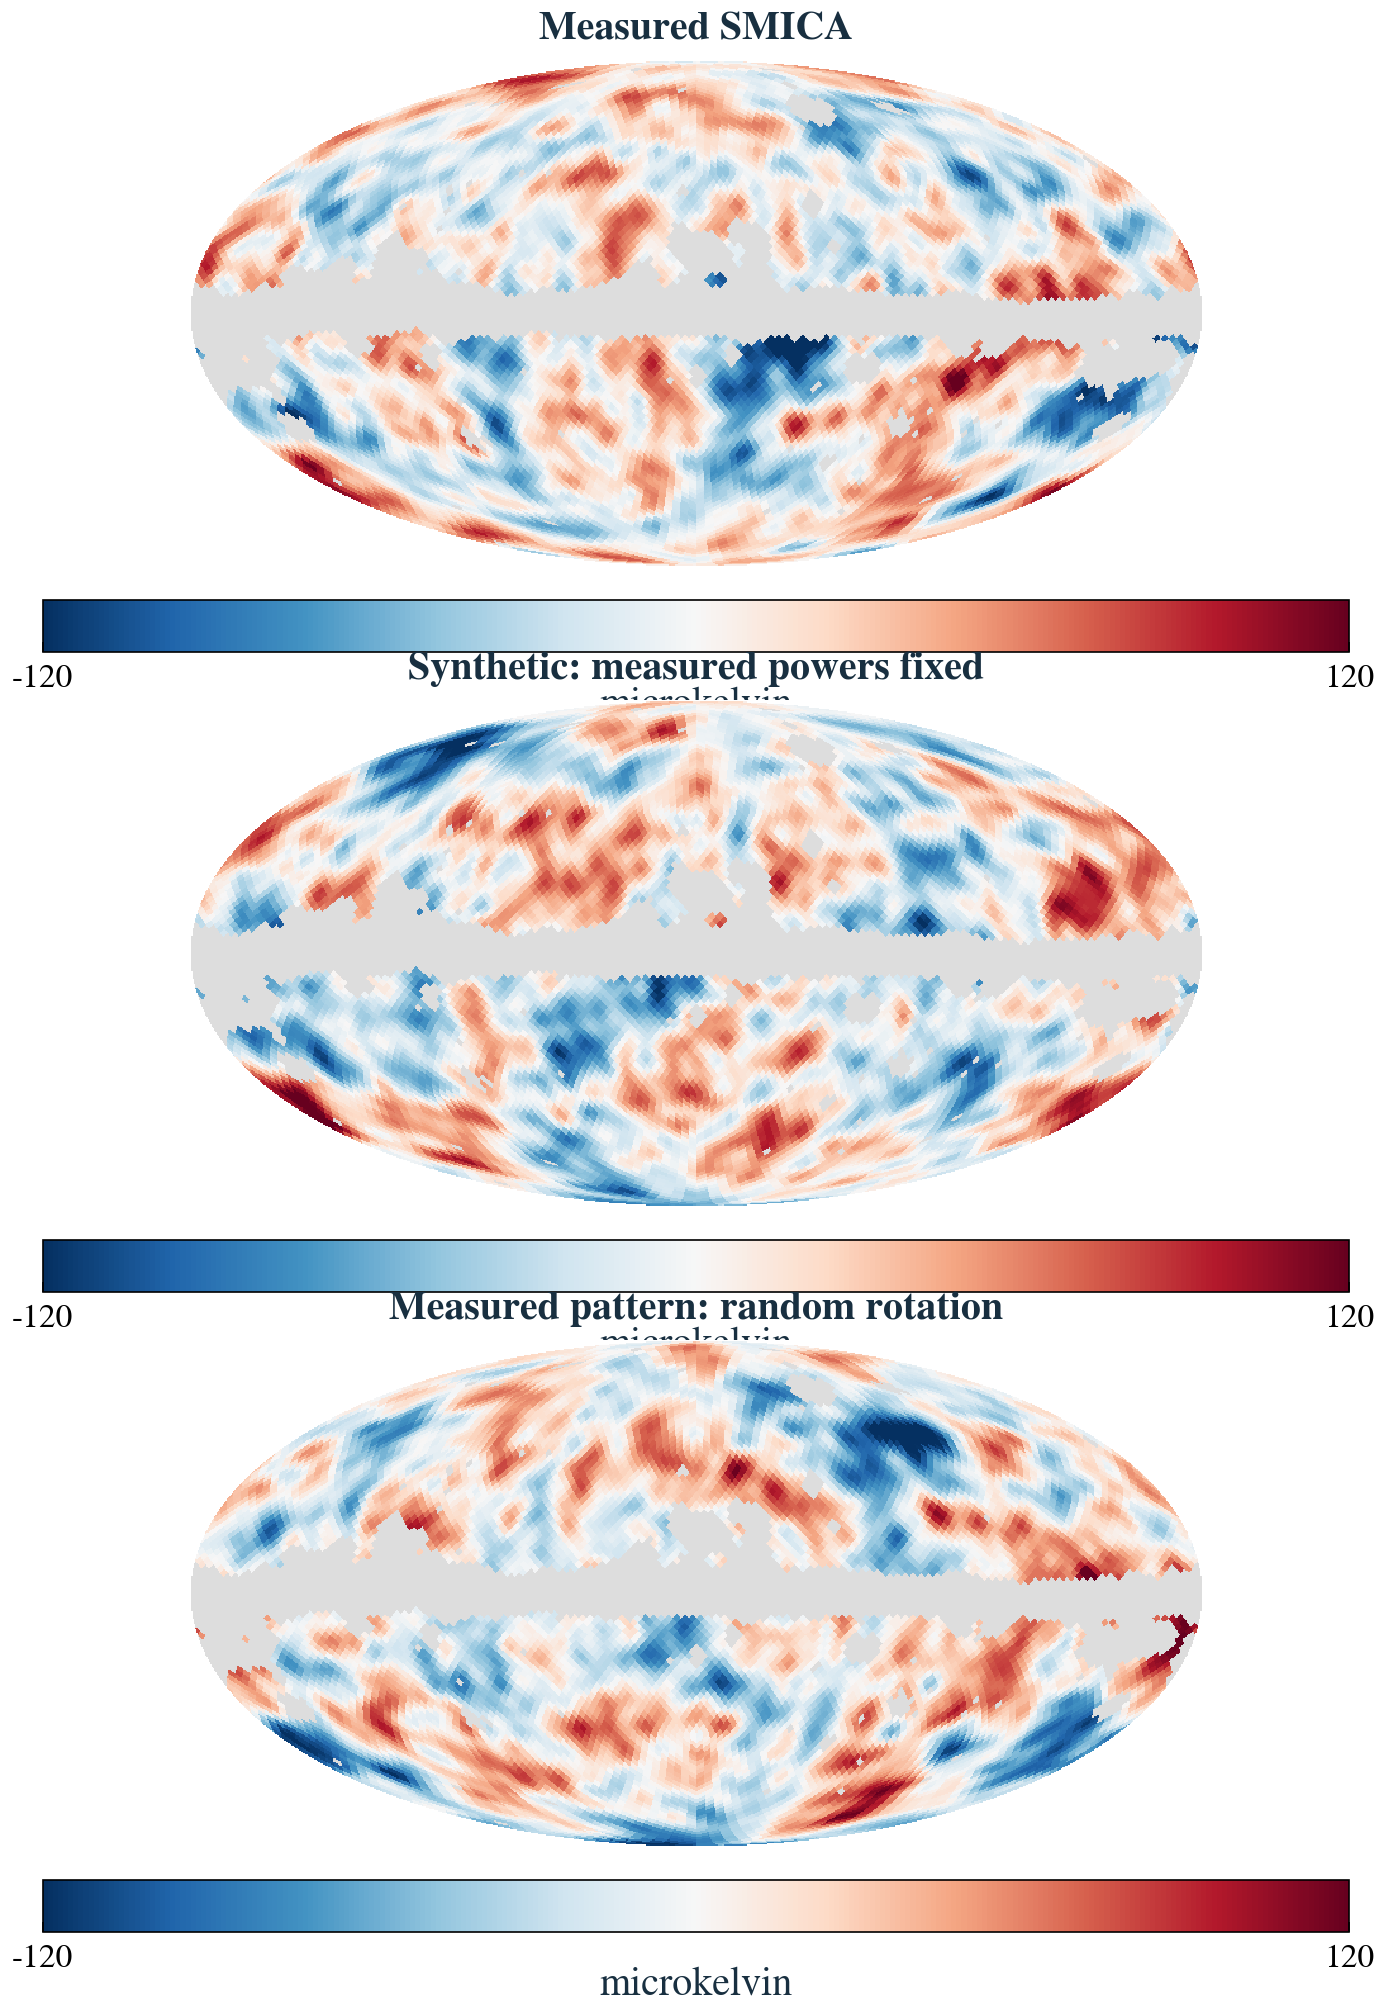

In [5]:
OUT=WORK/'results/conditional'
OUT.mkdir(parents=True,exist_ok=True)
fig=plt.figure(figsize=(11,8))
for j,(a,label) in enumerate([(observed_alm,'Measured SMICA'),(conditional_alm,'Synthetic: measured powers fixed'),(rotated,'Measured pattern: random rotation')],1):
    sky=hp.alm2map(hp.almxfl(a,window),config['nside'],pol=False)
    visible=hp.ma(estimator.project(sky)); visible.mask=~estimator.mask
    hp.mollview(visible,fig=fig.number,sub=(3,1,j),min=-120,max=120,cmap='RdBu_r',badcolor='#dddddd',title=label,unit='microkelvin')
save(fig,OUT,'notebook_conditional_maps')
display(Image(filename=str(OUT/'notebook_conditional_maps.png')))

## 6. Inspect the frozen protocol
Reference sets fit ranks and envelope scales; calibration sets set thresholds and compute tails; held-out sets check behavior. The three nulls ask different questions and their probabilities must not be pooled.

In [6]:
print(json.dumps(config,indent=2))
print('Null realizations:',3*sum(config[k] for k in ['n_reference','n_calibration','n_validation']))
print('Paired injected maps:',config['n_injection']*len(config['injection_amplitudes']))

{
  "seed": 20261108,
  "n_reference": 1024,
  "n_calibration": 4096,
  "n_validation": 1024,
  "input_lmax": 128,
  "nside": 32,
  "correlation_lmax": 95,
  "smoothing_fwhm_deg": 5.0,
  "mask_min_fraction": 0.95,
  "axis_nside": 2,
  "theta_min_deg": 60,
  "theta_max_deg": 180,
  "theta_step_deg": 1,
  "alpha": 0.05,
  "n_injection": 1024,
  "injection_amplitudes": [
    0.0,
    0.05,
    0.1,
    0.2,
    0.3
  ],
  "injection_axis_lon_lat_deg": [
    225.0,
    -27.0
  ],
  "status": "Retrospective exploratory extension. Ensemble counts, grid, statistics, direction and amplitudes fixed before executing this extension; not preregistered independent discovery tests. Conditional ensembles are distinct hypotheses and are never pooled for significance."
}
Null realizations: 18432
Paired injected maps: 5120


## 7. Execute the full analysis
This cell runs the actual ensembles, all four masked-sky diagnostics, finite-grid envelopes, power-preservation checks and paired injections. It does not substitute previously saved results.

In [7]:
result=run(WORK,config,OUT)
print('Elapsed seconds:',result['elapsed_seconds'])

gaussian: 512/6144; 1.9s


gaussian: 1024/6144; 3.7s


gaussian: 1536/6144; 5.5s


gaussian: 2048/6144; 7.6s


gaussian: 2560/6144; 9.9s


gaussian: 3072/6144; 11.8s


... (36 outputs left out)

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


Completed in 135.8s: /mnt/c/Users/biswa/Documents/GitHub/cmb-anomaly-lab/results/conditional


Elapsed seconds: 135.76963671100003


## 8. Compare the conditional questions
The table reports one-sided local tails and the four-diagnostic family calibration within each ensemble. A conditional probability is not a corrected version of the Gaussian probability.

# Conditional morphology and orientation experiments

Author: Biswajit Jana

Exploratory CMB-only randomization diagnostics. The fixed powers and rotated pattern come from a processed full-sky component-separated map, including uncertain foreground regions. Smoothing before masking can mix these regions into retained pixels. Neither conditional ensemble removes this systematic uncertainty or constitutes an independent observation.

| Ensemble | S lower tail | Variance lower tail | Pseudo-parity lower tail | Hemisphere upper tail | Four-test family |
|---|---:|---:|---:|---:|---:|
| Gaussian theory | 0.00805 | 0.04808 | 0.01904 | 0.08201 | 0.03564 |
| Measured powers fixed | 0.02221 | 0.02441 | 0.26117 | 0.02831 | 0.07444 |
| Measured pattern rotated | 0.07152 | 0.04979 | 0.25384 | 0.49817 | 0.13791 |

These are three different null hypotheses; their p-values are not multiplied, pooled, or combined with earlier studies. Counting intervals, independent validation and analytic closure are in [results.json](results.json).

Per ensemble: 1024 reference, 4096 calibration and 1024 held-out validation skies. Three ensembles total 18,432 realizations.



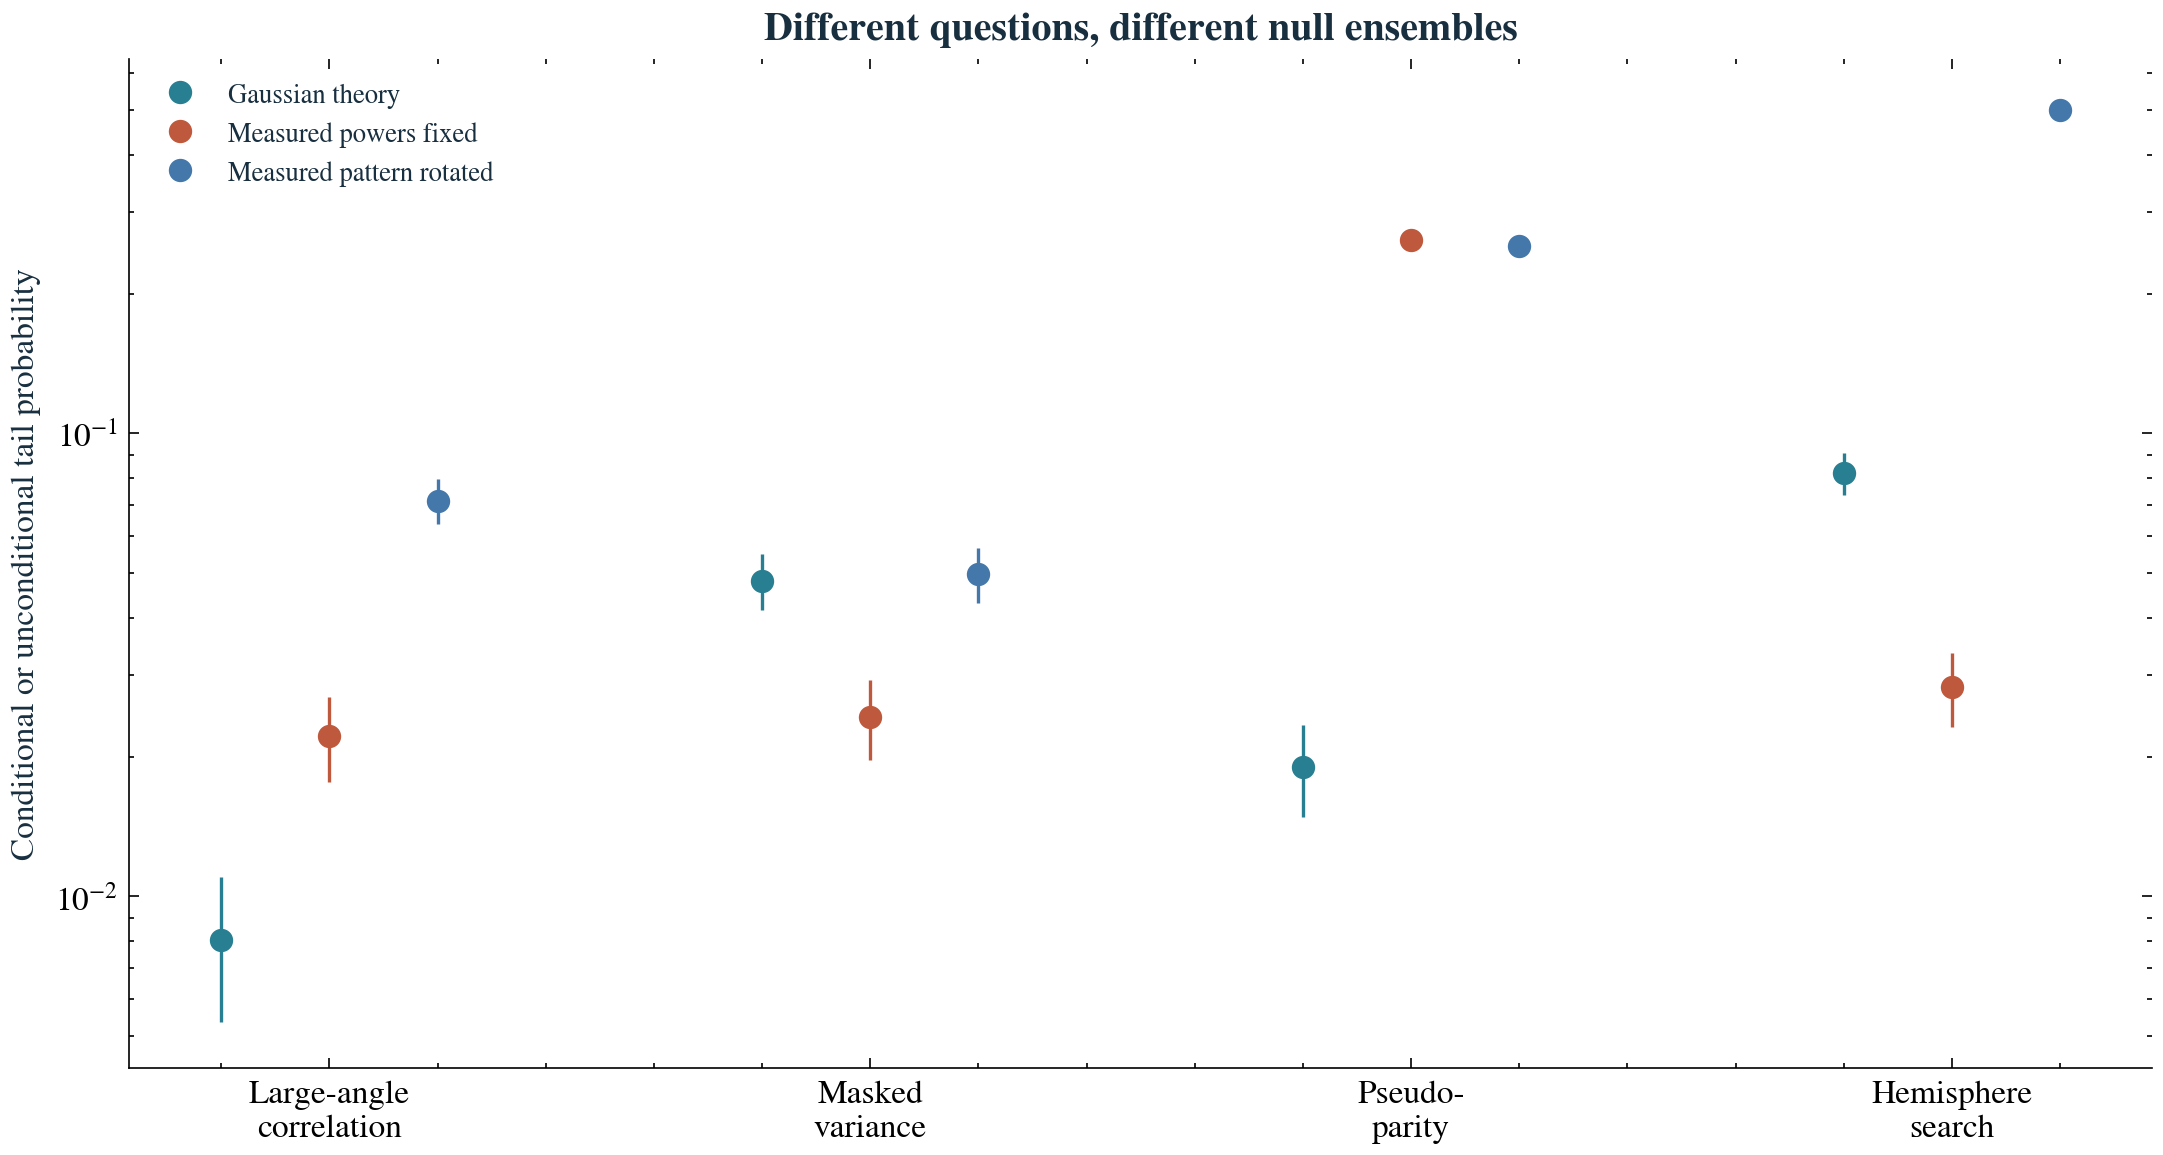

In [8]:
summary=(OUT/'SUMMARY.md').read_text()
table=summary.split('![Conditional tails]')[0]
display(Markdown(table))
display(Image(filename=str(OUT/'figures/conditional_tails.png')))

## 9. Check entire correlation curves
$$M(C)=\max_{\theta\in\{60^\circ,\ldots,180^\circ\}} |(C(\theta)-\mu_{\rm ref}(\theta))/s_{\rm ref}(\theta)|.$$
The envelope is calibrated on an independent sample and checked on held-out skies. It is simultaneous only on the declared 121-angle grid. Its two-sided score does not measure the same event as a small S integral.

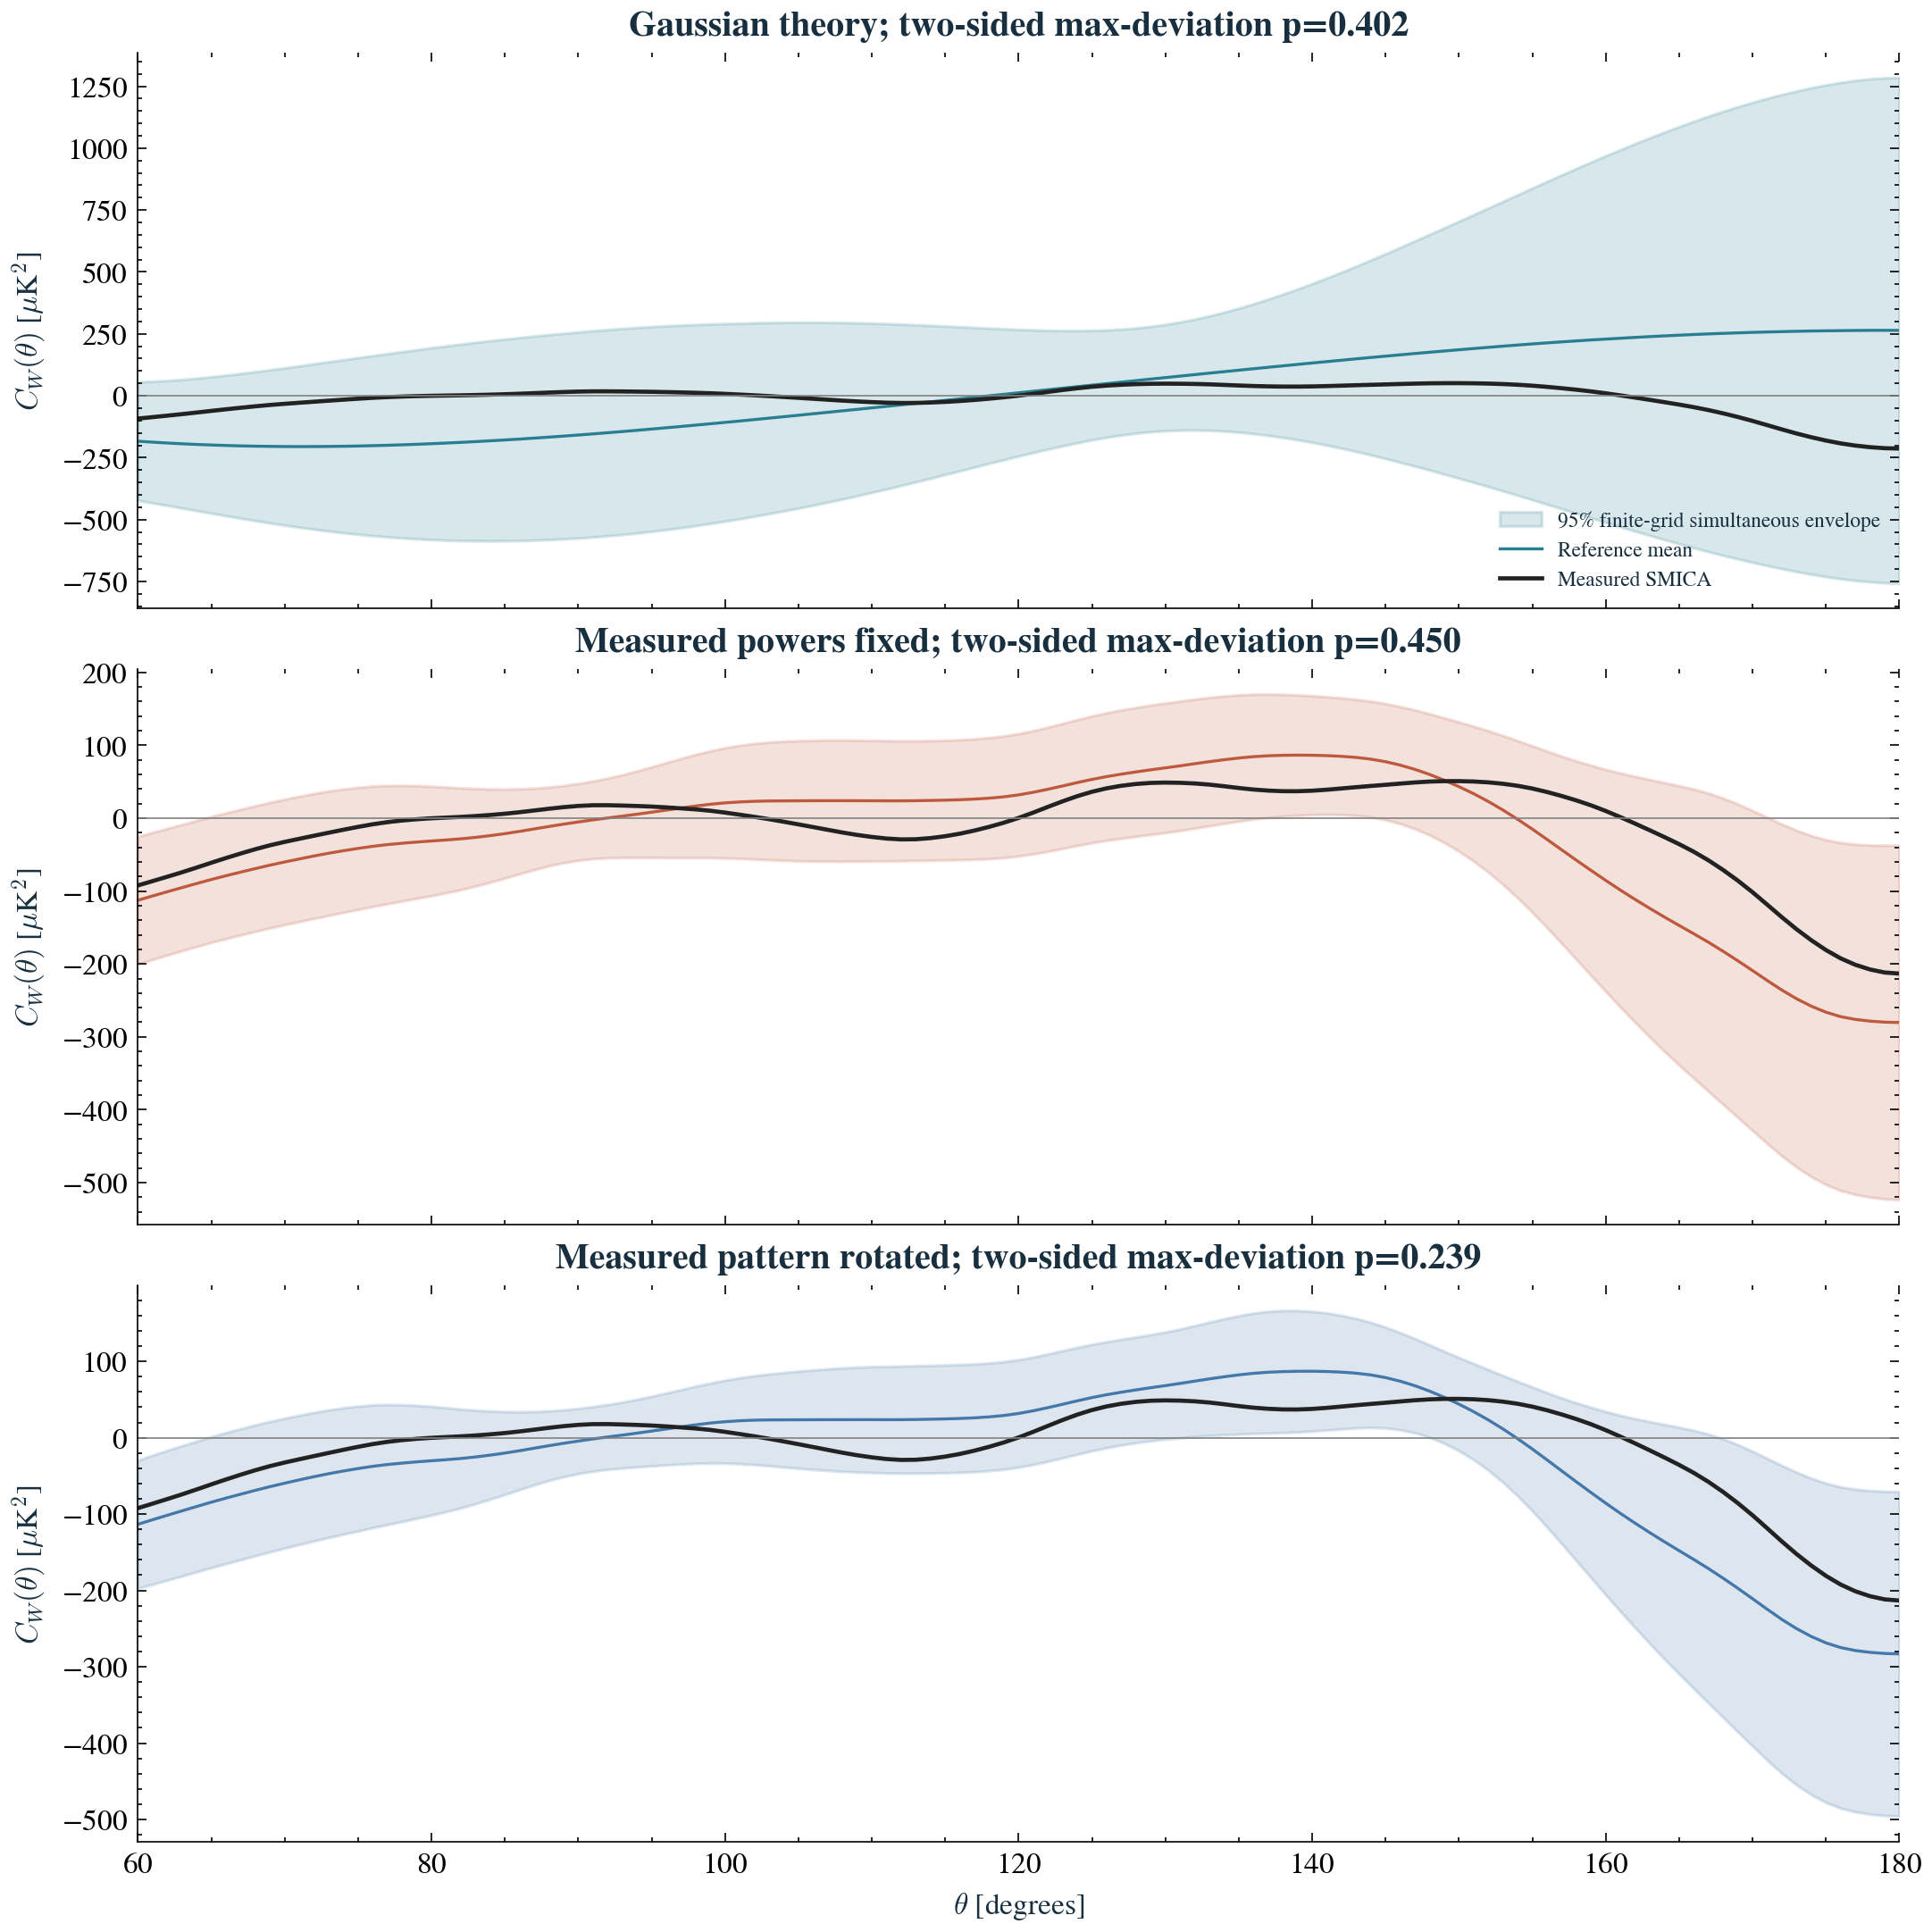

gaussian coverage: {'hits': 970, 'n': 1024, 'rate': 0.947265625, 'ci95': [0.9317501902391336, 0.960139433829932]}
Analytic projected-variance closure: {'analytic': 2087.657814809686, 'calibration_mean': 2087.9747700806347, 'standard_errors': 0.059254762875903734}
fixed_power coverage: {'hits': 969, 'n': 1024, 'rate': 0.9462890625, 'ci95': [0.9306585400154328, 0.9592847053237007]}
Analytic projected-variance closure: {'analytic': 1739.623047948094, 'calibration_mean': 1738.5844322964228, 'standard_errors': -0.963014328160305}
rotation coverage: {'hits': 983, 'n': 1024, 'rate': 0.9599609375, 'ci95': [0.9460721820238926, 0.9711167811843953]}
Analytic projected-variance closure: {'analytic': 1739.623047948094, 'calibration_mean': 1740.3250051676794, 'standard_errors': 0.5430940112372732}


In [9]:
display(Image(filename=str(OUT/'figures/simultaneous_envelopes.png')))
for name,r in result['ensembles'].items():
    print(name,'coverage:',r['simultaneous_band']['independent_validation_coverage'])
    print('Analytic projected-variance closure:',r['variance_closure'])

## 10. Measure the detector's sensitivity
$$T_A(\hat n)=[1+A\hat n\cdot\hat p]T_{\rm smoothed}(\hat n).$$
This illustrative signal is injected **after smoothing**. It is not a primordial transfer model or a measurement of A. Each amplitude uses the same underlying skies, with a fixed axis chosen before execution. Every trial repeats the 24-axis search.

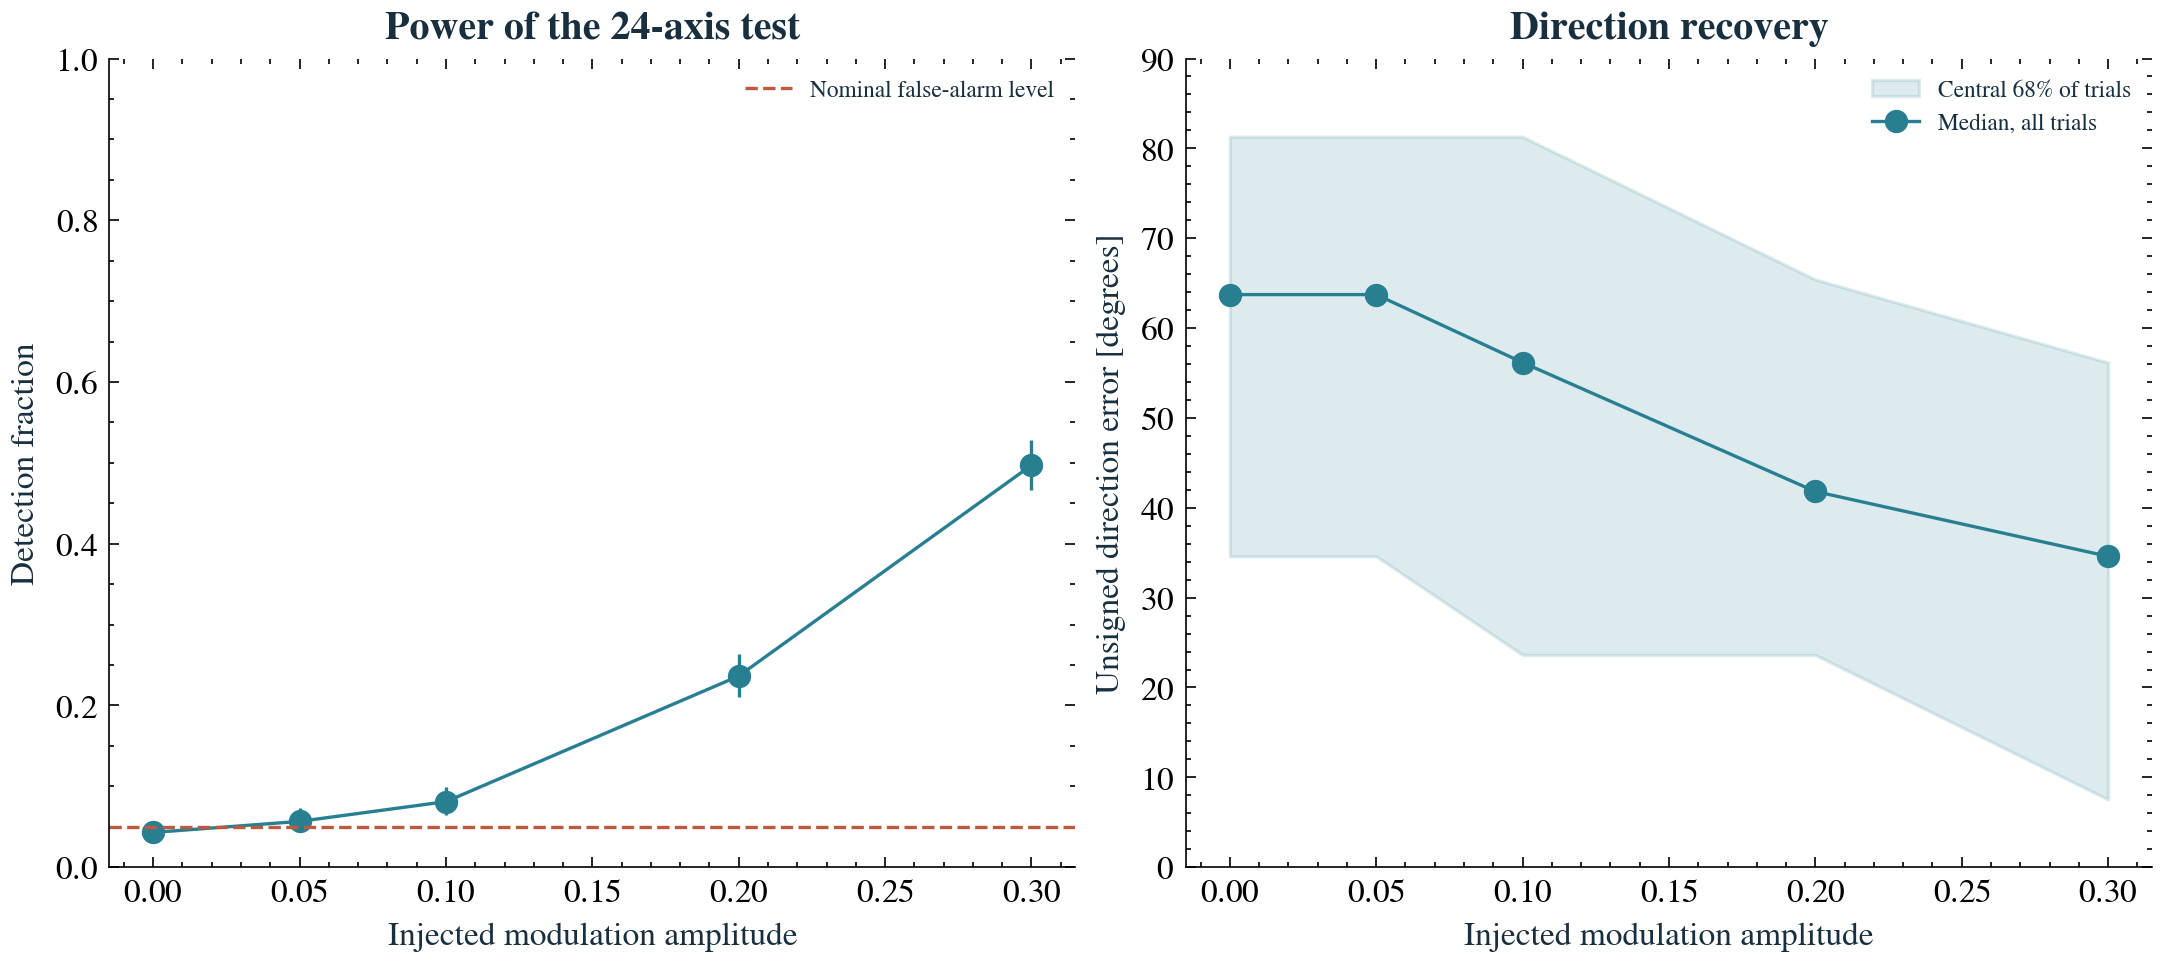

Fixed detection threshold: 0.32887467322881125
A= 0.0 detection: {'hits': 44, 'n': 1024, 'rate': 0.04296875, 'ci95': [0.03139183332587829, 0.05725680384339795]} median unsigned axis error: 63.72537059224333
A= 0.05 detection: {'hits': 58, 'n': 1024, 'rate': 0.056640625, 'ci95': [0.043287016971251625, 0.07260905274977554]} median unsigned axis error: 63.72537059224333
A= 0.1 detection: {'hits': 83, 'n': 1024, 'rate': 0.0810546875, 'ci95': [0.06507414893654577, 0.09949019761865384]} median unsigned axis error: 56.16473823201102
A= 0.2 detection: {'hits': 242, 'n': 1024, 'rate': 0.236328125, 'ci95': [0.21060804715902193, 0.26357329287790676]} median unsigned axis error: 41.81216062841632
A= 0.3 detection: {'hits': 509, 'n': 1024, 'rate': 0.4970703125, 'ci95': [0.46600410931112035, 0.5281534005462823]} median unsigned axis error: 34.59532575544599


In [10]:
display(Image(filename=str(OUT/'figures/injection_recovery.png')))
print('Fixed detection threshold:',result['injection']['threshold'])
for row in result['injection']['rows']:
    print('A=',row['amplitude'],'detection:',row['detection'],'median unsigned axis error:',row['median_axis_error_deg'])

## 11. Independently validate saved results
Recount the published CSV tails and injected detections, check source hashes, exact power conservation, ensemble variance closure and held-out envelope coverage.

In [11]:
check=subprocess.run([sys.executable,str(WORK/'scripts/validate_conditional.py')],check=True,capture_output=True,text=True)
print(check.stdout)

{
  "checks": {
    "gaussian": {
      "variance_closure_standard_errors": 0.059254762875903734,
      "held_out_coverage": {
        "hits": 970,
        "n": 1024,
        "rate": 0.947265625,
        "ci95": [
          0.9317501902391336,
          0.960139433829932
        ]
      },
      "max_tail_validation_difference_standard_errors": 2.056336946859098
    },
    "fixed_power": {
      "variance_closure_standard_errors": 0.963014328160305,
      "held_out_coverage": {
        "hits": 969,
        "n": 1024,
        "rate": 0.9462890625,
        "ci95": [
          0.9306585400154328,
          0.9592847053237007
        ]
      },
      "max_tail_validation_difference_standard_errors": 1.1555688191577753
    },
    "rotation": {
      "variance_closure_standard_errors": 0.5430940112372732,
      "held_out_coverage": {
        "hits": 983,
        "n": 1024,
        "rate": 0.9599609375,
        "ci95": [
          0.9460721820238926,
          0.9711167811843953
        ]
   

## 12. Inspect the limits before interpreting the numbers
Full-sky component-separated harmonics include uncertain Galactic regions. Filtering before masking can mix those regions into retained pixels. Noise, foreground residuals and cosmological-parameter uncertainty are not propagated. These retrospective randomization diagnostics establish neither a new physical origin nor a project-wide discovery significance.

In [12]:
print(result['interpretation'])
print(result['injection']['interpretation'])
print('Executed scientific source hashes:')
print(json.dumps(result['source_sha256'],indent=2))

Exploratory CMB-only randomization diagnostics. The fixed powers and rotated pattern come from a processed full-sky component-separated map, including uncertain foreground regions. Smoothing before masking can mix these regions into retained pixels. Neither conditional ensemble removes this systematic uncertainty or constitutes an independent observation.
Detection power of a toy dipole modulation applied AFTER 5-degree smoothing; not an inferred primordial amplitude. Each row uses the same underlying skies, so rates across amplitudes are correlated. The maximizing axis is unsigned and searched over 24 directions.
Executed scientific source hashes:
{
  "scripts/analyze_conditional.py": "34f6f2b43b2ef1017d8809d64d1bf1501cbd4d61a6b35863648ec97357e6e5fb",
  "src/cmb_lab/conditional.py": "b7dcb0cb2e1a48c97b55ac4c5f2152be977c1b73441424375e1cff22c3bc0589",
  "src/cmb_lab/map_statistics.py": "6dba14ef617e79eca15549487b3716989374f6027ae5f8813a62b89675068e92",
  "scripts/analyze_maps.py": "2eb6

## 13. Export the numerical work
Downloadable CSV, JSON and figures are included. Raw FITS and intermediate ensembles are excluded from this small archive.

In [13]:
from zipfile import ZipFile, ZIP_DEFLATED
archive=WORK/'results/cmb_conditional_research_outputs.zip'
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file() and p.suffix in {'.csv','.json','.png','.pdf','.md'}:
            z.write(p,p.relative_to(WORK/'results'))
print('Export:',archive.name,'| bytes:',archive.stat().st_size)
from IPython.display import FileLink
display(FileLink(str(archive)))

Export: cmb_conditional_research_outputs.zip | bytes: 2586972


/mnt/c/Users/biswa/Documents/GitHub/cmb-anomaly-lab/results/cmb_conditional_research_outputs.zip

## Sources and credit
- [Planck 2018 VII](https://arxiv.org/abs/1906.02552)
- [Efstathiou, Ma and Hanson (2010)](https://arxiv.org/abs/0911.5399)
- [Akrami et al. (2014)](https://arxiv.org/abs/1402.0870)
- [Full method derivation and limitations](https://biswajit1999.github.io/cmb-anomaly-lab/docs/conditional-methods.html)

**Biswajit Jana · CMB Anomaly Lab.** Measurements: ESA/Planck; distribution: NASA/IPAC IRSA. Software: HEALPix/healpy, NumPy, SciPy, SciencePlots. AI assistance is disclosed in AUTHORS.md.